# Algoritmo A*

Busca el camino más corto entre dos nodos como Dijkstra, pero ordena la cola por $f(n) = g(n) + h(n)$: el coste real desde el origen $g(n)$ más una estimación $h(n)$ de lo que falta hasta el destino. Si la heurística es **admisible** ($h(n)$ nunca supera el coste real restante) el camino es óptimo, y cuanto mejor estima, menos nodos expande. En el peor caso ($h = 0$) es Dijkstra: $O((V + E) \log V)$.

Las rejillas son listas de filas con `#` para los muros, como en el algoritmo de Lee.

## 1. A* en una rejilla con distancia Manhattan

Con movimientos en horizontal o vertical de coste 1, la distancia Manhattan $|f_1 - f_2| + |c_1 - c_2|$ nunca sobreestima. Encontrar el camino de `S` a `E`, dibujarlo con `*` y contar los nodos expandidos.

In [1]:
import heapq
from math import inf

laberinto = [
    "S....#........",
    ".###.#.######.",
    ".#...#......#.",
    ".#.#####.##.#.",
    ".#........#...",
    ".#####.##.###.",
    ".......#.....E",
]
MOVS_4 = [(0, 1, 1), (1, 0, 1), (0, -1, 1), (-1, 0, 1)]

def busca(rejilla, simbolo):
    return next((f, c) for f, fila in enumerate(rejilla) for c, v in enumerate(fila) if v == simbolo)

def libre(rejilla, f, c):
    return 0 <= f < len(rejilla) and 0 <= c < len(rejilla[0]) and rejilla[f][c] != "#"

def transitable(rejilla, n, v):
    # en diagonal no se puede cortar la esquina de un muro
    return libre(rejilla, *v) and libre(rejilla, n[0], v[1]) and libre(rejilla, v[0], n[1])

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def ruta(previo, destino):
    camino = []
    while destino is not None:
        camino.append(destino)
        destino = previo[destino]
    return camino[::-1]

def a_estrella(rejilla, origen, destino, h, movimientos=MOVS_4):
    g, previo = {origen: 0}, {origen: None}
    # (f, h, nodo): a igual f, primero el que parece más cerca
    cola, cerrados, expandidos = [(h(origen, destino), h(origen, destino), origen)], set(), []
    while cola:
        _, _, n = heapq.heappop(cola)
        if n in cerrados:
            continue
        cerrados.add(n)
        expandidos.append(n)
        if n == destino:
            return g[n], ruta(previo, destino), expandidos
        for df, dc, coste in movimientos:
            v = (n[0] + df, n[1] + dc)
            if v not in cerrados and transitable(rejilla, n, v) and g[n] + coste < g.get(v, inf):
                g[v], previo[v] = g[n] + coste, n
                hv = h(v, destino)
                heapq.heappush(cola, (g[v] + hv, hv, v))
    return None, None, expandidos

def dibuja_texto(rejilla, camino):
    filas = [list(fila) for fila in rejilla]
    for f, c in camino[1:-1]:
        filas[f][c] = "*"
    print("\n".join("".join(fila) for fila in filas))

coste, camino, expandidos = a_estrella(laberinto, busca(laberinto, "S"), busca(laberinto, "E"), manhattan)
print("Coste:", coste, " nodos expandidos:", len(expandidos))
dibuja_texto(laberinto, camino)

Coste: 23  nodos expandidos: 31
S....#........
*###.#.######.
*#...#......#.
*#.#####.##.#.
*#....****#...
*#####*##*###.
*******#.****E


## 2. Comparación con Dijkstra y BFS

Dijkstra es A* con $h = 0$ y, con costes unitarios, da lo mismo que BFS. Comparar los nodos expandidos en una rejilla grande con obstáculos aleatorios y un muro entre origen y destino, y comprobar en rejillas aleatorias que los tres dan la misma distancia.

In [2]:
import random
from collections import deque

def sin_heuristica(a, b):
    return 0

def bfs(rejilla, origen, destino):
    dist, cola, expandidos = {origen: 0}, deque([origen]), 0
    while cola:
        n = cola.popleft()
        expandidos += 1
        if n == destino:
            return dist[n], expandidos
        for df, dc, _ in MOVS_4:
            v = (n[0] + df, n[1] + dc)
            if libre(rejilla, *v) and v not in dist:
                dist[v] = dist[n] + 1
                cola.append(v)
    return None, expandidos

def rejilla_aleatoria(filas, columnas, densidad, origen, destino):
    rejilla = [["#" if random.random() < densidad else "." for _ in range(columnas)] for _ in range(filas)]
    rejilla[origen[0]][origen[1]] = rejilla[destino[0]][destino[1]] = "."
    return rejilla

random.seed(11)
origen, destino = (12, 3), (12, 36)
grande = rejilla_aleatoria(25, 40, 0.2, origen, destino)
for f in range(3, 22):
    grande[f][20] = "#"

distancia, expandidos_bfs = bfs(grande, origen, destino)
coste_dijkstra, _, expandidos_dijkstra = a_estrella(grande, origen, destino, sin_heuristica)
coste_a, _, expandidos_a = a_estrella(grande, origen, destino, manhattan)
assert distancia == coste_dijkstra == coste_a
print("Distancia:", distancia)
print(f"Expandidos: BFS {expandidos_bfs}, Dijkstra {len(expandidos_dijkstra)}, A* {len(expandidos_a)}")

random.seed(1)
for _ in range(300):
    o, d = (random.randrange(10), random.randrange(12)), (random.randrange(10), random.randrange(12))
    r = rejilla_aleatoria(10, 12, 0.3, o, d)
    assert bfs(r, o, d)[0] == a_estrella(r, o, d, sin_heuristica)[0] == a_estrella(r, o, d, manhattan)[0]

Distancia: 53
Expandidos: BFS 746, Dijkstra 749, A* 323


## 3. Heurística admisible y no admisible

Multiplicar la heurística por un factor $w > 1$ la hace no admisible: A* va más directo y expande menos nodos, pero puede devolver un camino más largo que el óptimo. Probar varios $w$ en la rejilla grande y contar en rejillas aleatorias cuántas veces el camino con $w = 3$ deja de ser óptimo (nunca puede ser más corto).

In [3]:
def ponderada(w):
    return lambda a, b: w * manhattan(a, b)

for w in (1, 1.5, 3, 10):
    coste, _, expandidos = a_estrella(grande, origen, destino, ponderada(w))
    print(f"w = {w:>4}: coste {coste}, expandidos {len(expandidos)}")

random.seed(2)
peores = 0
for _ in range(300):
    o, d = (random.randrange(10), random.randrange(12)), (random.randrange(10), random.randrange(12))
    r = rejilla_aleatoria(10, 12, 0.3, o, d)
    optimo = bfs(r, o, d)[0]
    coste = a_estrella(r, o, d, ponderada(3))[0]
    assert a_estrella(r, o, d, manhattan)[0] == optimo
    if optimo is not None:
        assert coste >= optimo
        peores += coste > optimo
print(peores, "de 300 caminos no óptimos con w = 3")

w =    1: coste 53, expandidos 323
w =  1.5: coste 53, expandidos 278
w =    3: coste 53, expandidos 182
w =   10: coste 53, expandidos 138
16 de 300 caminos no óptimos con w = 3


## 4. Movimiento diagonal y distancia octil

Con 8 direcciones (rectas de coste 1, diagonales de coste $\sqrt{2}$, sin cortar esquinas de muros) la distancia Manhattan sobreestima. La heurística admisible es la distancia octil: $h = \max(\Delta f, \Delta c) + (\sqrt{2} - 1) \min(\Delta f, \Delta c)$. Comprobarla contra Dijkstra con diagonales y ver qué pasa si se usa Manhattan.

In [4]:
from math import isclose, sqrt

MOVS_8 = MOVS_4 + [(1, 1, sqrt(2)), (1, -1, sqrt(2)), (-1, 1, sqrt(2)), (-1, -1, sqrt(2))]

def octil(a, b):
    df, dc = abs(a[0] - b[0]), abs(a[1] - b[1])
    return max(df, dc) + (sqrt(2) - 1) * min(df, dc)

for nombre, h in (("Dijkstra", sin_heuristica), ("A* octil", octil), ("A* Manhattan", manhattan)):
    coste, _, expandidos = a_estrella(grande, origen, destino, h, MOVS_8)
    print(f"{nombre:<13} coste {coste:.3f}, expandidos {len(expandidos)}")

random.seed(3)
peores = 0
for _ in range(300):
    o, d = (random.randrange(10), random.randrange(12)), (random.randrange(10), random.randrange(12))
    r = rejilla_aleatoria(10, 12, 0.3, o, d)
    optimo = a_estrella(r, o, d, sin_heuristica, MOVS_8)[0]
    coste_octil = a_estrella(r, o, d, octil, MOVS_8)[0]
    coste_manhattan = a_estrella(r, o, d, manhattan, MOVS_8)[0]
    if optimo is None:
        assert coste_octil is None and coste_manhattan is None
    else:
        assert isclose(coste_octil, optimo)
        assert coste_manhattan > optimo - 1e-9
        peores += coste_manhattan > optimo + 1e-9
print(peores, "de 300 caminos no óptimos con Manhattan y diagonales")

Dijkstra      coste 45.042, expandidos 738
A* octil      coste 45.042, expandidos 408
A* Manhattan  coste 46.556, expandidos 314
5 de 300 caminos no óptimos con Manhattan y diagonales


## 5. Dibujar el camino en la rejilla

Dibujar con `matplotlib`, sobre la rejilla grande, los nodos expandidos y el camino de Dijkstra, A* con Manhattan, A* con $w = 3$ y A* con diagonales.

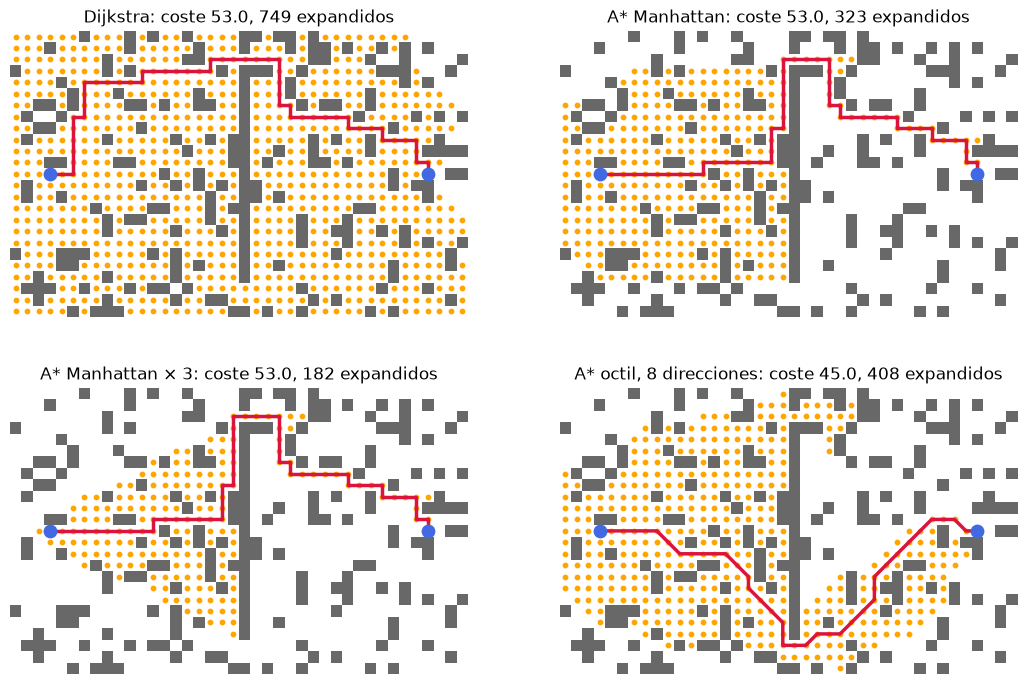

In [5]:
import matplotlib.pyplot as plt

casos = [("Dijkstra", sin_heuristica, MOVS_4), ("A* Manhattan", manhattan, MOVS_4),
         ("A* Manhattan × 3", ponderada(3), MOVS_4), ("A* octil, 8 direcciones", octil, MOVS_8)]
fig, ejes = plt.subplots(2, 2, figsize=(13, 8.5))
for eje, (titulo, h, movimientos) in zip(ejes.flat, casos):
    coste, camino, expandidos = a_estrella(grande, origen, destino, h, movimientos)
    eje.imshow([[x == "#" for x in fila] for fila in grande], cmap="Greys", vmax=1.5)
    eje.scatter([c for _, c in expandidos], [f for f, _ in expandidos], s=10, color="orange")
    eje.plot([c for _, c in camino], [f for f, _ in camino], color="crimson", linewidth=2.5)
    eje.scatter([origen[1], destino[1]], [origen[0], destino[0]], s=80, color="royalblue", zorder=3)
    eje.set_title(f"{titulo}: coste {coste:.1f}, {len(expandidos)} expandidos")
    eje.axis("off")
plt.show()